# Homework 6

## Setup
### Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from pathlib import Path
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.metrics import (mean_squared_error, root_mean_squared_error,
                             r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

### Training Settings

In [ ]:
housing_epochs = 350
cancer_epochs = 180
housing_lr = 0.001
cancer_lr = 0.001
batch_size = 32
housing_patience = 45
cancer_patience = 30

### Helper Functions

In [ ]:
def housing_preprocessor(frame):
    numerical = frame.select_dtypes(include=np.number).columns.tolist()
    categorical = frame.select_dtypes(exclude=np.number).columns.tolist()
    return ColumnTransformer([
        ('numeric', StandardScaler(), numerical),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore',
                                      sparse_output=False), categorical)
    ])


def regression_results(y_true, y_pred):
    return {
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R²': r2_score(y_true, y_pred)
    }


def classification_results(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0)
    }


def predict_nn(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(np.asarray(X), dtype=torch.float32)).numpy().reshape(-1)


def make_loader(X, y, size):
    dataset = TensorDataset(torch.tensor(np.asarray(X), dtype=torch.float32),
                            torch.tensor(np.asarray(y), dtype=torch.float32).reshape(-1, 1))
    return DataLoader(dataset, batch_size=size, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

### Neural Network Functions

In [ ]:
def make_housing_network(n_features):
    return nn.Sequential(nn.Linear(n_features, 64), nn.ReLU(),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))


def make_cancer_network(n_features):
    return nn.Sequential(nn.Linear(n_features, 64), nn.ReLU(),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))


def train_network(X_train, y_train, build_model, learning_rate, epochs,
                  X_val=None, y_val=None, patience=None, classification=False):
    torch.manual_seed(SEED)
    model = build_model(X_train.shape[1])
    loss_fn = nn.BCEWithLogitsLoss() if classification else nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate,
                                  weight_decay=0.001 if not classification else 0.0001)
    loader = make_loader(X_train, y_train, batch_size)
    history = []
    best_loss = float('inf')
    best_epoch = epochs
    stale = 0

    for epoch in range(1, epochs + 1):
        model.train()
        for x_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x_batch), y_batch)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            x = torch.tensor(np.asarray(X_train), dtype=torch.float32)
            y = torch.tensor(np.asarray(y_train), dtype=torch.float32).reshape(-1, 1)
            train_logits = model(x)
            train_loss = loss_fn(train_logits, y).item()
            row = {'Epoch': epoch, 'Training Loss': train_loss}
            if classification:
                row['Training Accuracy'] = ((train_logits >= 0).float() == y).float().mean().item()

            if X_val is not None:
                vx = torch.tensor(np.asarray(X_val), dtype=torch.float32)
                vy = torch.tensor(np.asarray(y_val), dtype=torch.float32).reshape(-1, 1)
                val_logits = model(vx)
                val_loss = loss_fn(val_logits, vy).item()
                row['Validation Loss'] = val_loss
                if classification:
                    row['Validation Accuracy'] = ((val_logits >= 0).float() == vy).float().mean().item()
                if val_loss < best_loss - 1e-6:
                    best_loss = val_loss
                    best_epoch = epoch
                    stale = 0
                else:
                    stale += 1

        history.append(row)
        if patience is not None and X_val is not None and stale >= patience:
            break

    return model, pd.DataFrame(history), best_epoch

## Problem 1
### Load Housing Dataset

In [ ]:
housing_paths = [Path('/content/drive/MyDrive/Colab Notebooks/Housing.csv'),
                 Path('Housing.csv'), Path('/mnt/data/Housing.csv')]

if not any(path.exists() for path in housing_paths):
    from google.colab import drive
    drive.mount('/content/drive')

housing_path = next((path for path in housing_paths if path.exists()), None)
if housing_path is None:
    raise FileNotFoundError('Housing.csv not found in Google Drive or notebook folder.')

housing = pd.read_csv(housing_path)
housing.columns = housing.columns.str.strip().str.lower()
print('Dataset shape:', housing.shape)
print('Columns:', housing.columns.tolist())

Dataset shape: (545, 13)
Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


### Select Input/Output Variables

In [ ]:
X_housing = housing.drop(columns='price')
y_housing = housing['price'].to_numpy(dtype=float)
print('Input shape:', X_housing.shape)
print('Output shape:', y_housing.shape)

Input shape: (545, 12)
Output shape: (545,)


### 80/20 Training/Test Split

In [ ]:
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    X_housing, y_housing, test_size=0.20, random_state=SEED
)
X_h_fit, X_h_val, y_h_fit, y_h_val = train_test_split(
    X_h_train, y_h_train, test_size=0.20, random_state=SEED
)
print('Training samples:', len(X_h_train))
print('Testing samples:', len(X_h_test))
print('Validation samples (within training):', len(X_h_val))

Training samples: 436
Testing samples: 109
Validation samples (within training): 88


### Normalize Input Data

In [ ]:
h_pre_val = housing_preprocessor(X_h_fit)
X_h_fit_scaled = h_pre_val.fit_transform(X_h_fit)
X_h_val_scaled = h_pre_val.transform(X_h_val)

y_h_scaler_val = StandardScaler()
y_h_fit_scaled = y_h_scaler_val.fit_transform(y_h_fit.reshape(-1, 1)).reshape(-1)
y_h_val_scaled = y_h_scaler_val.transform(y_h_val.reshape(-1, 1)).reshape(-1)
print('Neural network input features:', X_h_fit_scaled.shape[1])

Neural network input features: 13


### Train Fully Connected Neural Network

In [ ]:
housing_model_val, housing_history, housing_best_epoch = train_network(
    X_h_fit_scaled, y_h_fit_scaled, make_housing_network,
    housing_lr, housing_epochs, X_h_val_scaled, y_h_val_scaled,
    patience=housing_patience
)
print('Architecture: Input -> 64 -> 32 -> 1 (ReLU)')
print('Learning rate:', housing_lr)
print('Batch size:', batch_size)
print('Epochs completed:', len(housing_history))
print('Selected epoch:', housing_best_epoch)
print('Minimum validation loss:', housing_history['Validation Loss'].min())

Architecture: Input -> 64 -> 32 -> 1 (ReLU)
Learning rate: 0.001
Batch size: 32
Epochs completed: 59
Selected epoch: 14
Minimum validation loss: 0.3683384656906128


### Training and Validation Loss

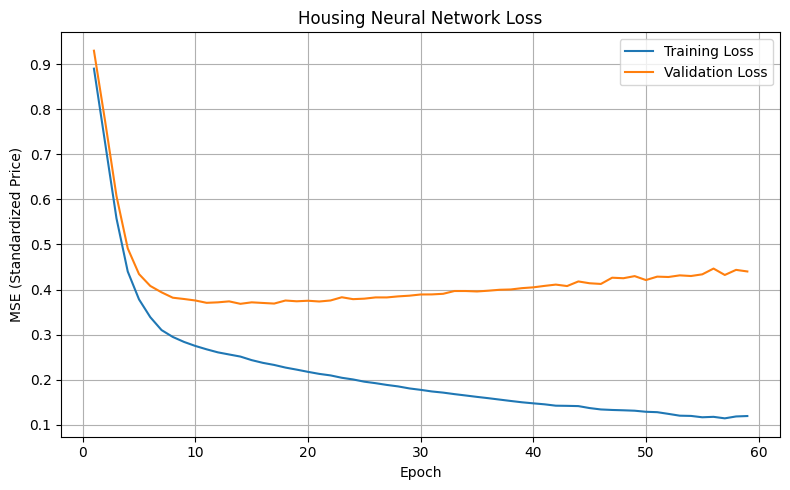

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(housing_history['Epoch'], housing_history['Training Loss'], label='Training Loss')
plt.plot(housing_history['Epoch'], housing_history['Validation Loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE (Standardized Price)')
plt.title('Housing Neural Network Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Final Neural Network Results

In [ ]:
h_pre_final = housing_preprocessor(X_h_train)
X_h_train_scaled = h_pre_final.fit_transform(X_h_train)
X_h_test_scaled = h_pre_final.transform(X_h_test)

y_h_scaler = StandardScaler()
y_h_train_scaled = y_h_scaler.fit_transform(y_h_train.reshape(-1, 1)).reshape(-1)

housing_model, _, _ = train_network(
    X_h_train_scaled, y_h_train_scaled, make_housing_network,
    housing_lr, housing_best_epoch
)

y_h_pred_scaled = predict_nn(housing_model, X_h_test_scaled)
y_h_pred = y_h_scaler.inverse_transform(y_h_pred_scaled.reshape(-1, 1)).reshape(-1)
housing_nn_metrics = regression_results(y_h_test, y_h_pred)
print(pd.Series(housing_nn_metrics).to_string())

MSE     1.764762e+12
RMSE    1.328444e+06
R²      6.508581e-01


### Linear Regression and SVR

In [ ]:
linear_model = Pipeline([
    ('preprocessing', housing_preprocessor(X_h_train)),
    ('model', LinearRegression())
])
svr_model = Pipeline([
    ('preprocessing', housing_preprocessor(X_h_train)),
    ('model', TransformedTargetRegressor(
        regressor=SVR(kernel='rbf', C=10, epsilon=0.1),
        transformer=StandardScaler()
    ))
])

linear_model.fit(X_h_train, y_h_train)
svr_model.fit(X_h_train, y_h_train)
linear_metrics = regression_results(y_h_test, linear_model.predict(X_h_test))
svr_metrics = regression_results(y_h_test, svr_model.predict(X_h_test))

### Regression Model Comparison

In [ ]:
housing_comparison = pd.DataFrame.from_dict({
    'Neural Network': housing_nn_metrics,
    'Linear Regression': linear_metrics,
    'SVR': svr_metrics
}, orient='index')
print(housing_comparison.round(4))
print('\nBest model (lowest RMSE):', housing_comparison['RMSE'].idxmin())

                            MSE          RMSE      R²
Neural Network     1.764762e+12  1.328444e+06  0.6509
Linear Regression  1.753273e+12  1.324112e+06  0.6531
SVR                2.154055e+12  1.467670e+06  0.5738

Best model (lowest RMSE): Linear Regression


## Problem 2
### Load Breast Cancer Dataset

In [ ]:
cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = (cancer.target == 0).astype(int)
print('Dataset shape:', X_cancer.shape)
print('Benign:', (y_cancer == 0).sum())
print('Malignant:', (y_cancer == 1).sum())

Dataset shape: (569, 30)
Benign: 357
Malignant: 212


### 80/20 Training/Test Split

In [ ]:
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_cancer, y_cancer, test_size=0.20, random_state=SEED, stratify=y_cancer
)
X_c_fit, X_c_val, y_c_fit, y_c_val = train_test_split(
    X_c_train, y_c_train, test_size=0.20, random_state=SEED, stratify=y_c_train
)
print('Training samples:', len(X_c_train))
print('Testing samples:', len(X_c_test))
print('Validation samples (within training):', len(X_c_val))

Training samples: 455
Testing samples: 114
Validation samples (within training): 91


### Standardize Input Data

In [ ]:
c_scaler_val = StandardScaler()
X_c_fit_scaled = c_scaler_val.fit_transform(X_c_fit)
X_c_val_scaled = c_scaler_val.transform(X_c_val)
print('Input features:', X_c_fit_scaled.shape[1])

Input features: 30


### Train Fully Connected Neural Network

In [ ]:
cancer_model_val, cancer_history, cancer_best_epoch = train_network(
    X_c_fit_scaled, y_c_fit, make_cancer_network,
    cancer_lr, cancer_epochs, X_c_val_scaled, y_c_val,
    patience=cancer_patience, classification=True
)
print('Architecture: 30 -> 64 -> 32 -> 1 (ReLU, Logits)')
print('Learning rate:', cancer_lr)
print('Batch size:', batch_size)
print('Epochs completed:', len(cancer_history))
print('Selected epoch:', cancer_best_epoch)
print('Minimum validation loss:', cancer_history['Validation Loss'].min())

Architecture: 30 -> 64 -> 32 -> 1 (ReLU, Logits)
Learning rate: 0.001
Batch size: 32
Epochs completed: 49
Selected epoch: 19
Minimum validation loss: 0.07535525411367416


### Training and Validation Loss

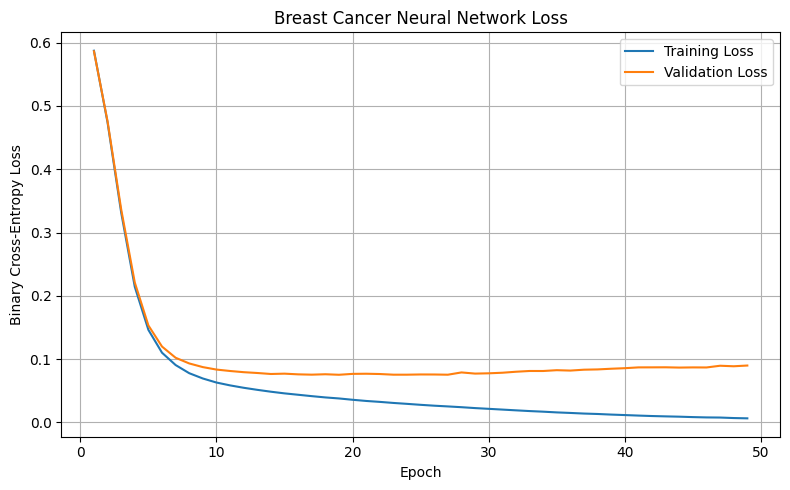

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(cancer_history['Epoch'], cancer_history['Training Loss'], label='Training Loss')
plt.plot(cancer_history['Epoch'], cancer_history['Validation Loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Breast Cancer Neural Network Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Training and Validation Accuracy

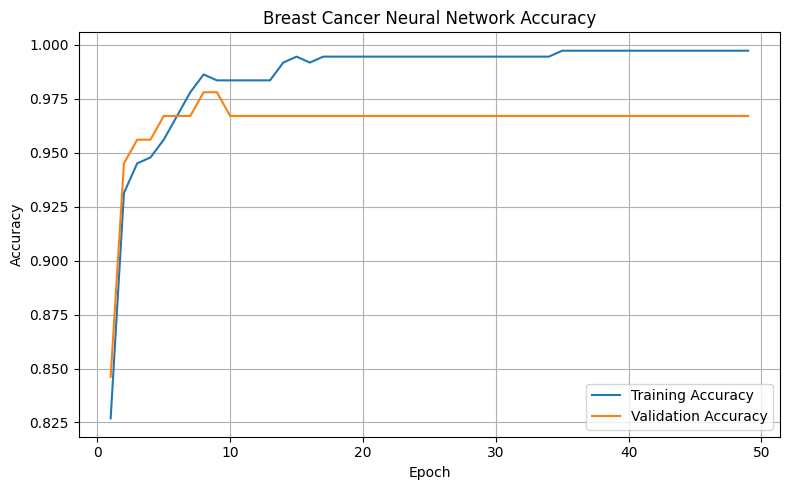

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(cancer_history['Epoch'], cancer_history['Training Accuracy'], label='Training Accuracy')
plt.plot(cancer_history['Epoch'], cancer_history['Validation Accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Breast Cancer Neural Network Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Final Neural Network Results

In [ ]:
c_scaler = StandardScaler()
X_c_train_scaled = c_scaler.fit_transform(X_c_train)
X_c_test_scaled = c_scaler.transform(X_c_test)

cancer_model, _, _ = train_network(
    X_c_train_scaled, y_c_train, make_cancer_network,
    cancer_lr, cancer_best_epoch, classification=True
)
cancer_logits = predict_nn(cancer_model, X_c_test_scaled)
cancer_nn_pred = (cancer_logits >= 0).astype(int)
cancer_nn_metrics = classification_results(y_c_test, cancer_nn_pred)
print(pd.Series(cancer_nn_metrics).round(4).to_string())

Accuracy     0.9825
Precision    1.0000
Recall       0.9524
F1           0.9756


### Confusion Matrix

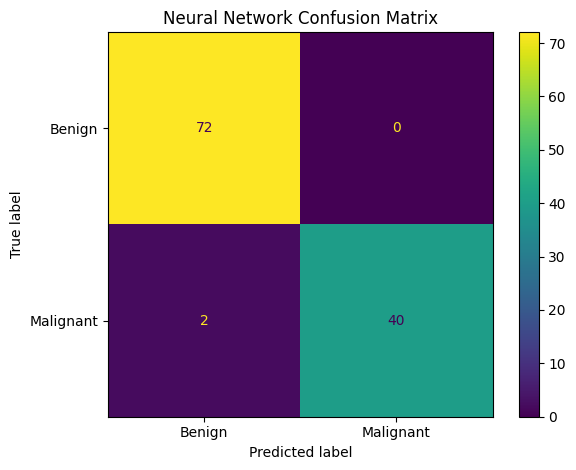

In [ ]:
cm = confusion_matrix(y_c_test, cancer_nn_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malignant']).plot()
plt.title('Neural Network Confusion Matrix')
plt.tight_layout()
plt.show()

### Logistic Regression and SVM

In [ ]:
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=3000, random_state=SEED))
])
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED))
])

logistic_model.fit(X_c_train, y_c_train)
svm_model.fit(X_c_train, y_c_train)
logistic_metrics = classification_results(y_c_test, logistic_model.predict(X_c_test))
svm_metrics = classification_results(y_c_test, svm_model.predict(X_c_test))

### Classification Model Comparison

In [ ]:
cancer_comparison = pd.DataFrame.from_dict({
    'Neural Network': cancer_nn_metrics,
    'Logistic Regression': logistic_metrics,
    'SVM': svm_metrics
}, orient='index')
print(cancer_comparison.round(4))
print('\nBest model (highest F1):', cancer_comparison['F1'].idxmax())

                     Accuracy  Precision  Recall      F1
Neural Network         0.9825      1.000  0.9524  0.9756
Logistic Regression    0.9649      0.975  0.9286  0.9512
SVM                    0.9737      1.000  0.9286  0.9630

Best model (highest F1): Neural Network
